# D24 / D25 / D26 — Combined Arrhenius Analysis

All measurements at the same spatial position on the surface, different file numbers and τ values.
If the physics is consistent, all datasets should fall on a single Arrhenius line.

**Datasets used:**
- D24 τ = 0.1 s and τ = 5 s
- D25 τ = 0.1 s and τ = 0.5 s  
- D26 τ = 0.1 s and τ = 1 s

**Inversion:**
$$D(T) = \frac{r_c^2}{4\tau\,[\mathrm{erf}^{-1}(P)]^2} \qquad \nu(T) = \frac{2D(T)}{a_0^2}$$

Only points with $0.1 < P < 0.9$ are used.

In [1557]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime, timezone
from scipy import constants 
import matplotlib.lines as mlines
from scipy.special import erfinv
from pathlib import Path
import pandas as pd
import csv


Temp_Path  = r"C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\DBTF\December data\Full_line_dataset" # This is where the binary npy files are stored
NPY_DIR     = Path(Temp_Path) # This is where those binary npy files go
r_c         = 1.5e-9      # m  capture radius. In the end it doesn't matter what this is -- it's entirely temperature-independent. 1.5 nm is reasonable.
a0          = 0.288e-9    # m  Ag(111) lattice constant
kB          = 8.617333e-5 # eV/K
kappa       = 1         #Transmission coefficient for crossing barrier, i.e if the molecule crosses the energy barrier, how often does it actually translate on the surface. Assume 100%
P_LO, P_HI  = 0.1, 0.9   # Limits for probabilities
N_TRIALS    = 50 
ADD_ZERO    = False
# ADD_ZERO    = True # Whether to add a zero at the start of the probability data (to represent the first trial)
Nu_intercept = 30

ENTROPY = False

In [1558]:
def read_data_summary(file_path, split=True, labels = [None, None]):
    """Read summary columns and detect the boundary between probability/Tau sections."""
    file = pd.read_csv(Path(file_path))

    temp = file["average_temperature"].to_numpy(dtype=float)
    temp_error = file["temperature_std"].to_numpy(dtype=float)
    tau = file["tau"].to_numpy(dtype=float)
    probabilities = file["probability"].to_numpy(dtype=float)
    if type(split) == int:
        return temp, temp_error, tau, probabilities, split
    elif split == True:
        # split is the index of the first row after the probability transition.
        candidates = np.flatnonzero(
            (probabilities[:-1] > 0.9) & np.isclose(probabilities[1:],0.0, atol = 0.08)
        )

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one probability transition from >0.9 to 0; "
                f"found {len(candidates)}."
            )

        split = int(candidates[0] + 1)

        if np.isclose(tau[split - 1], tau[split]):
            raise ValueError(
                f"Probability transition is at index {split}, but Tau does not "
                "change at that boundary."
            )

        print(f"{labels} Detected split before row {split}       Tau changes from {tau[split - 1]} to {tau[split]}")
        # print(f"Tau changes from {tau[split - 1]} to {tau[split]}")

        return temp, temp_error, tau, probabilities, split
    else:
        return temp, temp_error, tau, probabilities, None

def convert_to_epoch(date_time):
    
    dt = datetime.strptime(date_time, "%Y-%m-%d %H:%M:%S.%f").replace(tzinfo=timezone.utc)

    epoch_seconds = dt.timestamp()
    return epoch_seconds

def make_arrays(filename, names, colours, markers=["o", "s"], label=[None,None], split=True, cooldown = False):
    """Read summary columns and detect the boundary between probability/Tau sections."""
    temp, temp_error, tau, P_values, split = read_data_summary(filename, split=split, labels=names)

    if cooldown:
         with Path(cooldown).open("r", newline="", encoding="utf-8") as file:
             filereader = csv.reader(file, delimiter = ',' )
             header = next(filereader, None) 
             cooldown_times = []
             cooldown_temps = []
             for i, row in enumerate(filereader):
                cooldown_time = convert_to_epoch(row[1].strip())
                cooldown_temp = float(row[2])
                if i == 0:
                    start_time = cooldown_time
                cooldown_times.append(cooldown_time-start_time)
                cooldown_temps.append(cooldown_temp)
             order = np.argsort(cooldown_times)
             cooldown_arr = [np.asarray(cooldown_times)[order], np.asarray(cooldown_temps)[order]]
            
    else:
        cooldown_arr = None
    if split:
        temp_first, temp_second = temp[:split], temp[split:]
        P_first, P_second = P_values[:split], P_values[split:]
        if cooldown_arr is not None:
            first_array = [names[0], [temp_first, temp_error[:split]],tau[:split][0], P_first, cooldown_arr,  colours[0], markers[0], label[0]]
            second_array = [names[1], [temp_second, temp_error[split:]],tau[split:][0], P_second,cooldown_arr,  colours[1], markers[1], label[1]]
        else:
            first_array = [names[0], [temp_first, temp_error[:split]],tau[:split][0], P_first,  colours[0], markers[0], label[0]]
            second_array = [names[1], [temp_second, temp_error[split:]],tau[split:][0], P_second,  colours[1], markers[1], label[1]]
        return first_array, second_array
    else:
        return [names[0], [temp, temp_error], tau[0], P_values, cooldown_arr, colours[0], markers[0], label[0]]

In [1559]:
      # Bernoulli trials per probability estimate

# ── Temperature axis range (adjust to taste!) ──────────────────────────────────
T_MIN = 1.5   # K
T_MAX = 4.8   # K

# ── Dataset definitions ───────────────────────────────────────────────────────
# Each entry: label, npy filename, tau (s), ASCII probability list
# arr[0] stored descending T; ASCII list in same descending-T order
# Datasets below taken from Freddie's email of Mon 08/06/2026 14:51

loops_21_11_1s = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\21.11-1s-loops-4.1K-summary.csv",["21.11.25 loops 1s"], ["#1f77b4"], split=False)
loops_21_11_1s_zeros = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\21.11-1s-loops-4.2K-ZEROS-summary.csv", ["21.11.25 loops 1s"], ["#03090c"], split=False)
loops_21_11_5s = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\21.11-5s-loops-summary.csv",["21.11.25 loops 5s"], ["#10ffdb"], split=False)
four_28K = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\4-2.8K_summary.csv",["Mostky nothing"], ["#38726a"], split=False)
twenty_11_cooldown1 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\20.11_cooldown1_summary.csv", ["20.11 cooldown 1"], ["#56D658"], split=False)


D14_1   = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D14_1_summary.csv",["D14 1s"], ["#1f77b4"], split=False)
D14_001 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D14_0.01_summary.csv",["D14 0.01s"], ["#1b2a35"], split=False)
D14_01  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D14_0.1_summary.csv",["D14 0.1s"], ["#8fcdfa"], split=False)

D10_01, D10_05 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D10_summary.csv", ["D10 0.1s", "D10 0.5s"], ["#5b7df8", "#00f7ff"],split = 15, cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D10_temperatures.csv")
D11_01, D11_05 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D11_summary.csv", ["D11 0.1s", "D11 0.5s"], ["#f85bf8", "#ff009d"],split = 54, cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D11_0.1_0.5_temperatures.csv")

D12_01  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D12_0.1_summary.csv",["D12 0.1s"], ["#1B8C19"], split=False)

D20_01,D20_5 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D20_summary.csv", ["D20 0.1s", "D20 5s"], ["#1f77b4", "#fe7041"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D20_temperatures.csv")
 
D21_01, D21_1 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D21_summary.csv", ["D21 0.1s", "D21 5s"], ["#617481", "#8684ff"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D21_temperatures.csv")


D24_01, D24_5  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D24_summary.csv", ["D24 0.1s", "D24 5s"], ["#1f77b4", "#873a48"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D24_temperatures.csv")

D25_01, D25_05 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D25_summary.csv", ["D25 0.1s", "D25 0.5s"], ["#ffc13a", "#ffdd00"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D25_temperatures.csv")

D26_01, D26_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D26_summary.csv", ["D26 0.1s", "D26 1s"], ["#2ca02c", "#00ff00"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D26_temperatures.csv")

D27_01, D27_05 = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D27_summary.csv", ["D27 0.1s", "D27 0.5s"], ["#d38b4d", "#ff9408"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D27_temperatures.csv")

D28_01, D28_1  =  make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D28_summary.csv", ["D28 0.1s", "D28 1s"], ["#0027e9", "#7ec6f3"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D28_temperatures.csv")

D31_01, D31_1  =  make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D31_summary.csv", ["D31 0.1s", "D31 1s"], ["#c8ae00", "#7dc90c"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D31_temperatures.csv")

D32_01, D32_1  =  make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D32_summary.csv", ["D32 0.1s", "D32 1s"], ["#00c8be", "#05606a"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D32_temperatures.csv")


D33_01, D33_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D33_summary.csv", ["D33 0.1s", "D33 1s"], ["#3b1665", "#ffbff5"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D33_temperatures.csv" )

D34_01, D34_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D34_summary.csv", ["D34 0.1s", "D34 1s"], ["#65f89e", "#1efc73"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D34_temperatures.csv" )

D35_01, D35_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D35_summary.csv", ["D35 0.1s", "D35 1s"], ["#11380D", "#349d2e"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D35_temperatures.csv" )

D36_01, D36_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D36_summary.csv", ["D36 0.1s", "D36 1s"], ["#7C1870", "#585abb"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D36_temperatures.csv" )

D37_01, D37_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D37_summary.csv", ["D37 0.1s", "D37 1s"], ["#0E8E00", "#ffbf00"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D37_temperatures.csv" )

D38_01, D38_1  = make_arrays(r"E:\Nanoscience data\DBTF\November_2\Summary_CSV\D38_summary.csv", ["D38 0.1s", "D38 1s"], ["#E12900", "#ff8e8e"], cooldown=r"E:\Nanoscience data\DBTF\November_2\Cooldown_CSV\D38_temperatures.csv" )



DATASETS = [
    # loops_21_11_1s,
    # loops_21_11_1s_zeros, #
    # loops_21_11_5s,
    # four_28K,
    # twenty_11_cooldown1,
    # D14_001,
    # D14_01,
    # D14_1,

    D10_01,
    D10_05,
    # D12_01,
    D11_01,
    D11_05,

    ### Group 1
    
    # D20_01,
    # D20_5,

    # D21_01,
    # D21_1,

    # D24_01,
    # D24_5,
    
    ### Start of group 2
    
    # D25_01,
    # D25_05,

    # D26_01,
    # D26_1 ,

    # D27_01,
    # D27_05,

    # D31_01,
    # D31_1,

    # D37_01,
    # D37_1,

    # ### Start of group 3

    # D32_01,
    # D32_1,

    # D33_01,
    # D33_1,

    # D28_01,
    # D28_1,
    

    # D38_01,
    # D38_1,
    
    # D34_01, D34_1,D35_01,D35_1, D36_01,D36_1, # Possible bad cooldowns

    # ('D22 τ=0.1s', 'data22_0pt1_pos2.npy', 0.1, [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.3,0.74,0.84,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1], "#f5a500", 'o','D22  τ = 0.1 s'),
    
    # ('D22 τ=0.5s', 'data22_0pt5_pos2.npy', 0.5,[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.06,0.22,0.56,0.84,0.96,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1], "#f5a500", '^','D22  τ = 0.5 s'),

]

# ── Per-series style: (colour, marker) ───────────────────────────────────────
# Legend order requested:
#   D24 0.1s → blue   circle
#   D25 0.1s → orange circle
#   D26 0.1s → green  circle
#   D25 0.5s → orange triangle
#   D26 1s   → green  square
#   D24 5s   → blue   diamond

STYLES = [
    {'color': '#1f77b4', 'marker': 'o', 'c_label': 'D1  τ = 0.1 s'},  # D24 0.1s -> Renamed D1 for Poster plotting
    {'color': '#1f77b4', 'marker': 'D', 'c_label': 'D1  τ = 5 s'},    # D24 5s
    {'color': '#ff7f0e', 'marker': 'o', 'c_label': 'D2  τ = 0.1 s'},  # D25 0.1s
    {'color': '#ff7f0e', 'marker': '^', 'c_label': 'D2  τ = 0.5 s'},  # D25 0.5s
    {'color': '#2ca02c', 'marker': 'o', 'c_label': 'D3  τ = 0.1 s'},  # D26 0.1s
    {'color': '#2ca02c', 'marker': 's', 'c_label': 'D3  τ = 1 s'},    # D26 1s
]

# Legend display order (indices into STYLES)
LEGEND_ORDER = [0, 2, 4, 3, 5, 1]  # D1○ D2○ D3○ D2△ D3□ D1◇

print('Datasets defined.')
print(loops_21_11_1s)
print(loops_21_11_1s_zeros)

['D20 0.1s', 'D20 5s'] Detected split before row 70       Tau changes from 0.1 to 5.0
['D21 0.1s', 'D21 5s'] Detected split before row 58       Tau changes from 0.1 to 5.0
['D24 0.1s', 'D24 5s'] Detected split before row 26       Tau changes from 0.1 to 5.0
['D25 0.1s', 'D25 0.5s'] Detected split before row 35       Tau changes from 0.1 to 0.5
['D26 0.1s', 'D26 1s'] Detected split before row 31       Tau changes from 0.1 to 1.0
['D27 0.1s', 'D27 0.5s'] Detected split before row 46       Tau changes from 0.1 to 0.5
['D28 0.1s', 'D28 1s'] Detected split before row 50       Tau changes from 0.1 to 1.0
['D31 0.1s', 'D31 1s'] Detected split before row 50       Tau changes from 0.1 to 1.0
['D32 0.1s', 'D32 1s'] Detected split before row 50       Tau changes from 0.1 to 1.0
['D33 0.1s', 'D33 1s'] Detected split before row 33       Tau changes from 0.1 to 1.0
['D34 0.1s', 'D34 1s'] Detected split before row 50       Tau changes from 0.1 to 1.0
['D35 0.1s', 'D35 1s'] Detected split before row 2

  Dataset               n       T range (K)            ν range (Hz)
  --------------------------------------------------------------------
  D10 0.1s              2  4.101 – 4.143  1.06e+02 – 1.18e+02 colour - #5b7df8 marker - o
2 2 2 2 2 2 2
  D10 0.5s              4  3.879 – 4.137  3.93e+01 – 7.04e+01 colour - #00f7ff marker - s
4 4 4 4 4 4 4
  D11 0.1s             28  1.889 – 2.308  1.12e+02 – 5.24e+03 colour - #f85bf8 marker - o
28 28 28 28 28 28 28
  D11 0.5s             13  1.884 – 2.284  2.24e+01 – 1.74e+03 colour - #ff009d marker - s
13 13 13 13 13 13 13


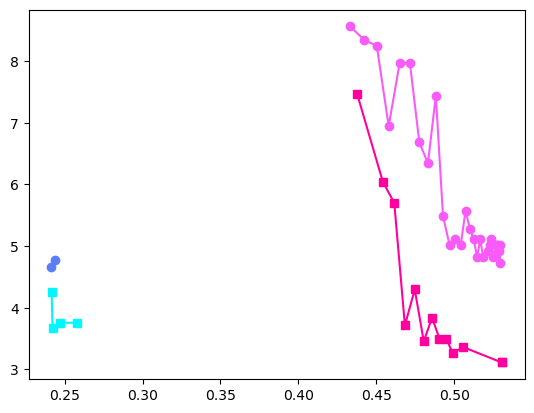

In [1560]:
# ── Load, invert, collect usable points ──────────────────────────────────────

results = []

print(f'  {"Dataset":18s}  {"n":>3}  {"T range (K)":>16}  {"ν range (Hz)":>22}')
print('  ' + '-'*68)

for i, (label, temps, tau, P_list, cooldown, color, marker, c_label) in enumerate(DATASETS):
    
    # style = STYLES[LEGEND_ORDER[i]]
    
    
    if type(temps) != list:
        version = "Old"
        arr   = np.load(NPY_DIR / temps)
        T_raw = arr[0]
    else:
        version = "New"
        T_raw = temps[0]

    P_raw = np.array(P_list)
    N     = min(len(T_raw), len(P_raw))
    T_raw, P_raw = T_raw[:N], P_raw[:N]

    mask  = (P_raw > P_LO) & (P_raw < P_HI)
    T_use = T_raw[mask]
    P_use = P_raw[mask]

    if mask.sum() == 0:
        print(f'  {label:18s}  no usable points')
        results.append(None)
        continue

    idx   = np.argsort(T_use)
    T_use = T_use[idx]
    P_use = P_use[idx]
    # P_use = np.append(P_use, 1)
    # T_use = np.append(T_use, 0)  # Append 1 to P for plotting purposes

    ei    = erfinv(P_use)
    D     = r_c**2 / (4 * tau * ei**2)
    nu    = 2 * D / a0**2

    
    # nu[-1] =  np.exp(30)  # Append zero to nu for plotting purposes
    # ei = np.append(ei, 1)  # Append zero to ei for plotting purposes
    
    print(f'  {label:18s}  {len(T_use):>3}  '
          f'{T_use.min():.3f} – {T_use.max():.3f}  '
          f'{nu.min():.2e} – {nu.max():.2e} colour - {color} marker - {marker}')

    # ── Uncertainties ──────────────────────────────────────────────────
    # Temperature std dev from arr[1] (same order as arr[0])
    if version == "Old":
        T_err_use = arr[1][:N][mask][idx]
    elif version == "New":
        T_err_use = temps[1][mask]

    # Bernoulli std error:  sigma_P = sqrt(P(1-P) / N_TRIALS)
    sigma_P = np.sqrt(P_use * (1 - P_use) / N_TRIALS)

    # Propagate sigma_P into sigma_nu:
    #   nu = r_c^2 / (2*tau*a0^2 * erfinv(P)^2)
    #   d(nu)/dP = nu * (-2/erfinv(P)) * d(erfinv(P))/dP
    #   d(erfinv(P))/dP = (sqrt(pi)/2) * exp(erfinv(P)^2)
    d_erfinv_dP = (np.sqrt(np.pi) / 2) * np.exp(ei**2)
    sigma_nu    = np.abs(nu * (-2 / ei) * d_erfinv_dP) * sigma_P

            
    if ADD_ZERO:
        T_use = np.append(T_use, 1000000000)
        nu = np.append(nu, np.exp(Nu_intercept))     # Append zero to nu for plotting purposes
        T_err_use = np.append(T_err_use, T_err_use[-1])
        # sigma_P   = np.append(sigma_P, 0)
        sigma_nu  = np.append(sigma_nu, sigma_nu[-1])

    print(len(T_use), len(P_use), len(D), len(nu), len(T_err_use), len(sigma_P), len(sigma_nu))
    results.append({'label': label, 'tau': tau,
                    'T': T_use, 'P': P_use, 'D': D, 'nu': nu,
                    'T_err': T_err_use, 'sigma_P': sigma_P, 'sigma_nu': sigma_nu, 'cooldown': cooldown,
                    'color': color, 'marker': marker, 'c_label': c_label})
# Append zero to nu for plotting purposes
    plt.plot(1/T_use, np.log(nu), marker=marker, color=color, label=label)
plt.show()
# for r in results:
#     print(r)


  Dataset  30        n        ΔE (meV)         ν₀ (Hz)       R² 
  ----------------------------------------------------------------------
  D10 0.1s              2  too few points for covariance (need ≥3) — skipped
  D10 0.5s              4    1.21 ± 2.00        1.53e+03 ± 8.78e+03   0.1549
  D11 0.1s             28    3.64 ± 0.28        4.98e+11 ± 8.14e+11   0.8648
  D11 0.5s             13    3.59 ± 0.70        3.98e+10 ± 1.57e+11   0.7070


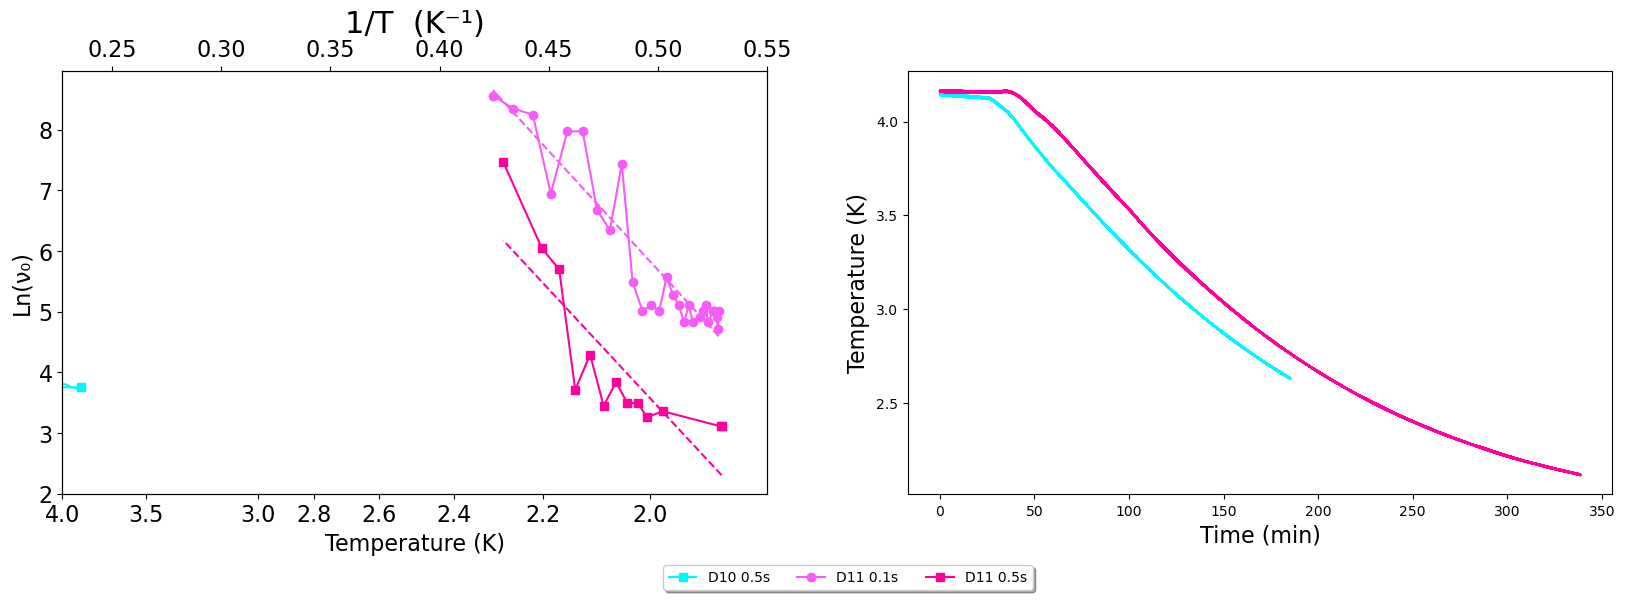

In [1561]:
# ── Per-dataset Arrhenius fits ────────────────────────────────────────────────
print(f'  {"Dataset ":7s} {str(Nu_intercept):7s} {"n":>3}  {"ΔE (meV)":>14}  {"ν₀ (Hz)":>14}  {"R²":>7} ')
print('  ' + '-'*70)
intercept_collection = []
intercept_collection_else = []
dE_collection = []

fig, [ax, ax_1] = plt.subplots(1, 2, figsize=(20, 5.5))

# ── Panel 1: P(T) — semi-transparent markers + erf fit ──────────────────────


for r in results:
    if r is None:
        print("No usable points: SKIP")
        continue
    if len(r['T']) < 3:
        print(f'  {r["label"]:18s}  {len(r["T"]):>3}  too few points for covariance (need ≥3) — skipped')
        r['slope'] = None; r['intercept'] = None
        r['dE'] = None; r['dE_err'] = None
        r['nu0'] = None; r['nu0_err'] = None; r['R2'] = None
        continue
    # plt.scatter(1/temp, np.log(nu), marker=r['marker'], color=r['color'], label=r['label'])
    # plt.show()
    tau = r['tau']
    temp = r['T']
    nu = r['nu']

    

    if ENTROPY:
        plot = np.log(nu/temp)
    else:
        plot = np.log(nu)

    (slope, intercept), cov = np.polyfit(1/temp, plot, 1, cov=True)
    dE      = -kB * slope
    dE_err  = kB * np.sqrt(cov[0, 0])
    nu0     = np.exp(intercept)
    nu0_err = nu0 * np.sqrt(cov[1, 1])

    ln_fit  = slope / temp + intercept
    ss_res  = np.sum((plot - ln_fit)**2)
    ss_tot  = np.sum((plot - np.mean(plot))**2)
    R2      = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    r['slope'] = slope; r['intercept'] = intercept
    r['dE'] = dE; r['dE_err'] = dE_err
    r['nu0'] = nu0; r['nu0_err'] = nu0_err; r['R2'] = R2

    print(f'  {r["label"]:18s}  {len(r["T"]):>3}  '
          f'{dE*1e3:>6.2f} ± {dE_err*1e3:.2f}  '
          f'{nu0:>14.2e} ± {nu0_err:.2e}  {R2:>7.4f}')
    intercept_collection.append(intercept)
    dE_collection.append(dE*1e3)

    ax.plot(1/temp, plot, marker=r['marker'], color=r['color'], label=r['label'])
    ax.plot(1/temp, ln_fit, color=r['color'], linestyle='--', label=None) #f'{r["label"]} fit')

    cooldown = r['cooldown']
    cooldown_time = cooldown[0]
    cooldown_temps = cooldown[1]
    # if i%2 == 0:
    #     plt_label = r['label']
    # else:
    #     plt_label = None
    ax_1.plot(np.array(cooldown_time)/60, cooldown_temps, color = r['color'], label=r['label'])
# fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ── Panel 1: P(T) — semi-transparent markers + erf fit ──────────────────────

tick_T    = np.array([2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.5, 4.0])
tick_invT = 1.0 / tick_T
in_range  = (tick_invT >= 1/4) & (tick_invT <= 1/T_MIN)
# ax.set_xlim(tick_inv[in_range2].min(), tick_inv[in_range2].max())
ax.set_xticks(tick_invT[in_range])
ax.set_xticklabels([f'{t:.1f}' for t in tick_T[in_range]], fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.set_xlabel("Temperature (K)", fontsize=16)
if ENTROPY:
    ax.set_ylabel("Ln(ν₀/T)", fontsize=16)
else:
    ax.set_ylabel("Ln(ν₀)", fontsize=16)
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())

ax_1.set_xlabel("Time (min)", fontsize=16)
ax_1.set_ylabel("Temperature (K)", fontsize=16)

tick_inv   = np.arange(0.25, 0.56, 0.05)
in_range2  = (tick_inv >= 1/4) & (tick_inv <= 1/T_MIN)
ax.set_xlim(tick_inv[in_range2].min(), tick_inv[in_range2].max())
ax_top.set_xticks(tick_inv[in_range2])
ax_top.set_xticklabels([f'{v:.2f}' for v in tick_inv[in_range2]], fontsize=16)
ax_top.set_xlabel('1/T  (K⁻¹)', fontsize=22)
# plt.xlabel("Temperature (K)")
# plt.ylabel("Ln(ν₀/T)")
ax.legend(loc='upper center', bbox_to_anchor=(1.115, -0.15),
          ncol=12, fancybox=True, shadow=True)
plt.show()

# print(intercept_collection)

In [1562]:
# ── Combined Arrhenius fit across all datasets ────────────────────────────────
def weighted_mean(data,scaling=1):
    """

    ChatGPT-ed


    Calculate inverse-variance weighted mean and uncertainties.

    Parameters
    ----------
    data : list
        List of [value, error] pairs.

    Returns
    -------
    mean : float
        Weighted mean.
    mean_err : float
        Uncertainty on weighted mean.
    chi_squared : float
        Chi-squared statistic.
    reduced_chi_squared : float
        Chi-squared divided by degrees of freedom.
    """

    data = np.array(data, dtype=float)

    values = data[:, 0]
    errors = data[:, 1]

    if len(values) < 2 or np.any(errors <= 0):
        raise ValueError("Need at least two measurements with positive errors.")

    # Calculate weights
    weights = 1 / errors**2

    # Weighted mean
    mean = np.sum(weights * values) / np.sum(weights)

    # Error on weighted mean
    mean_err = np.sqrt(1 / np.sum(weights))

    # Chi-squared
    chi_squared = np.sum(((values - mean) / errors)**2)

    # Reduced chi-squared
    dof = len(values) - 1
    reduced_chi_squared = chi_squared / dof

    return mean*scaling, mean_err*scaling, chi_squared, reduced_chi_squared

T_all  = np.concatenate([r['T']  for r in results if r])
nu_all = np.concatenate([r['nu'] for r in results if r])

if ENTROPY:
    plot_all = np.log(nu_all/T_all)
else:
    plot_all = np.log(nu_all)

(slope_all, int_all), cov_all = np.polyfit(1/T_all, plot_all, 1, cov=True)
dE_all      = -kB * slope_all
dE_all_err  = kB * np.sqrt(cov_all[0, 0])
nu0_all     = np.exp(int_all)
nu0_all_err = nu0_all * np.sqrt(cov_all[1, 1])

ln_fit_all = slope_all / T_all + int_all
ss_res_all = np.sum((plot_all - ln_fit_all)**2)
ss_tot_all = np.sum((plot_all - np.mean(plot_all))**2)
R2_all     = 1 - ss_res_all / ss_tot_all

print('Combined fit across all datasets:')
print(f'  N points : {len(T_all)}')
print(f'  ΔE       : {dE_all*1e3:.2f} ± {dE_all_err*1e3:.2f} meV')
print(f'  ν₀       : {nu0_all:.3e} ± {nu0_all_err:.2e} Hz')
print(f'  R²       : {R2_all:.4f}')



Combined fit across all datasets:
  N points : 47
  ΔE       : -0.10 ± 0.22 meV
  ν₀       : 1.028e+02 ± 1.22e+02 Hz
  R²       : 0.0050


    D10 0.5s	 ΔE = 1.21 ± 2.00 meV (165.14%)	ν₀ = 1.53e+03  ± 8.78e+03Hz  (573.87%)	ν₀ = 7.33  ± 9.08Hz  (123.83%) R2 0.1549
    D11 0.1s	 ΔE = 3.64 ± 0.28 meV (7.75%)	ν₀ = 4.98e+11  ± 8.14e+11Hz  (163.55%)	ν₀ = 26.93  ± 27.43Hz  (101.83%) R2 0.8648
    D11 0.5s	 ΔE = 3.59 ± 0.70 meV (19.41%)	ν₀ = 3.98e+10  ± 1.57e+11Hz  (393.22%)	ν₀ = 24.41  ± 25.78Hz  (105.61%) R2 0.7070

    Entropy: False, ADD_ZERO: False, Nu_intercept: 30

    Mean Values ± Standard Deviation:
    ΔE_mean: 1.90 ± 1.32 meV (69.26%)
    intercept_mean: 20.16 ± 8.52 Hz (42.26%)

    Weighted Mean Values:
    ΔE_W_mean = 3.59 ± 0.26 meV (7.22%)  with reduced chi squared 0.7208692602804436	 (1.44 / 2)
    intercept_W_mean = 10.79 ± 8.175 Hz (75.75%) with reduced chi squared 0.3852587389277806	  (0.77 / 2)


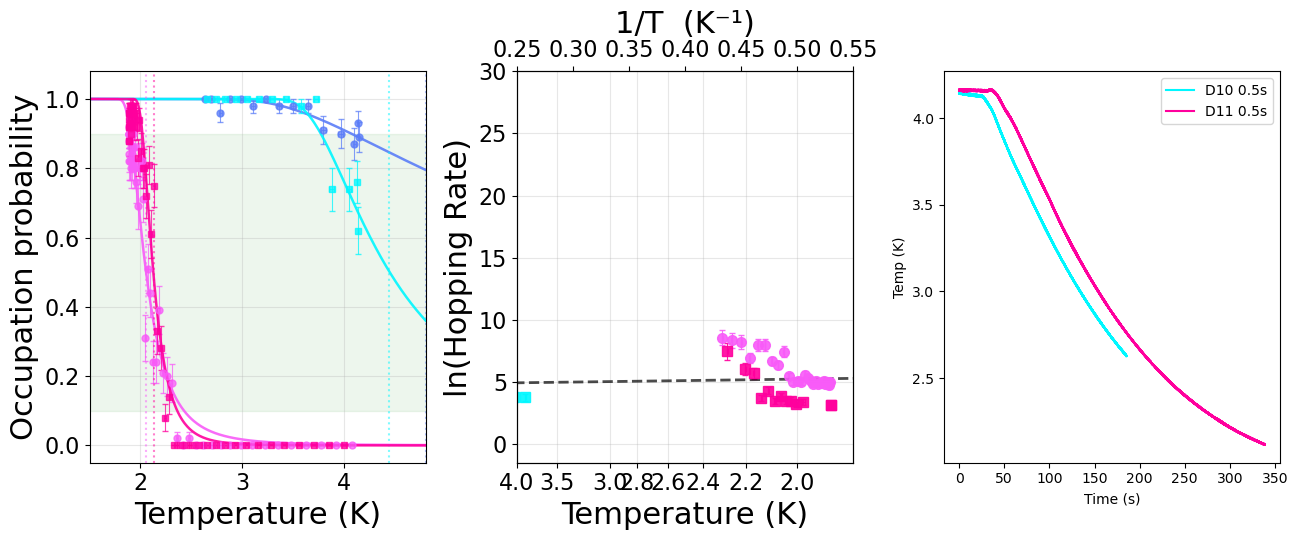

Saved SVG and PNG.


<Figure size 640x480 with 0 Axes>

In [1563]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))

# ── Panel 1: P(T) — semi-transparent markers + erf fit ──────────────────────
ax = axes[0]
T_fit_dense  = np.linspace(T_MIN, T_MAX, 400)
phys_fits    = []
t_collection = []
nu_0_collection = []    # collect (label, dE, dE_err) from physical model fits
count = 0
for i, (label, temps, tau, P_list, cooldown_arr, color, marker, c_label) in enumerate(DATASETS):
    
    # style = STYLES[LEGEND_ORDER[i]]
    
    if type(temps) != list:
        version = "Old"
        arr   = np.load(NPY_DIR / temps)
        T_raw = arr[0]
    else:
        version = "New"
        T_raw = temps[0]
    P_raw = np.array(P_list)
    N     = min(len(T_raw), len(P_raw))
    idx   = np.argsort(T_raw[:N])
    T_s   = T_raw[:N][idx]
    P_s   = P_raw[:N][idx]

    # Semi-transparent markers + error bars
    if version == "Old":
        T_err_s   = arr[1][:N][idx]
    elif version == "New":
        T_err_s = temps[1][:N][idx]
    else:
        raise ValueError(f"Unknown version {version}")
    sigma_P_s = np.sqrt(P_s * (1 - P_s) / N_TRIALS)
    ax.errorbar(T_s, P_s,
                xerr=T_err_s, yerr=sigma_P_s,
                fmt=marker, color=color,
                markersize=5, linewidth=0, alpha=0.75,
                elinewidth=0.8, capsize=2, ecolor=color)

    # Physical model:  P_occ(T) = erf( r_c / (a0 * sqrt(nu0 * tau)) * exp(dE / (2*kB*T)) )
    # Two free parameters: dE (barrier, eV) and nu0 (attempt frequency, Hz)
    # tau, r_c, a0, kB are all known — nothing hidden in the fit
    from scipy.special import erf as sp_erf
    from scipy.optimize import curve_fit

    def physical_model(T, dE, nu0_fit):
        arg = (r_c / (a0 * np.sqrt(nu0_fit * tau))) * np.exp(dE / (2 * kB * T))
        return sp_erf(arg)

    try:
        # Unweighted fit — all 50-trial points have equal sampling effort.
        # Bernoulli errors are used for display only, not to weight the fit,
        # because weighting by 1/sigma^2 over-emphasises the low-P tail
        # (small sigma there) and distorts the transition temperature.
        popt, pcov = curve_fit(physical_model, T_s, P_s,
                               p0=[5e-3, 1e12],
                               bounds=([1e-5, 1e0], [0.5, 1e30]),
                               maxfev=20000)
        
        ax.plot(T_fit_dense, physical_model(T_fit_dense, *popt),
                            color=color, linewidth=1.8, alpha=0.9,
                            linestyle='-')

        ## find the point where it crosses 0.5 for each fit
        T_cross_05 = T_fit_dense[np.argmin(np.abs(physical_model(T_fit_dense, *popt) - 0.5))]
        t_collection.append(T_cross_05)
        ax.axvline(T_cross_05, color=color, linestyle=':', alpha=0.5)
       
        # ax.text( T_cross_05, 1.03, r["label"],transform=ax.get_xaxis_transform(), ha="center",va="bottom")

        perr = np.sqrt(np.diag(pcov))
        # print(f'  {label:18s} {Nu_intercept} {ADD_ZERO} ΔE = {dE_all*1e3:.2f} ± {dE_all_err*1e3:.2f} meV'
        #       f'   ν₀ = {popt[1]:.2e} Hz'
        #       f' colour - {color} marker - {marker}')
        # Store physical-model fit results
        dictionary = dict(label=label, tau=tau,
                          dE=popt[0], dE_err=perr[0],
                          nu0=popt[1], style=[color, marker], T_cross_05=T_cross_05)
        phys_fits.append([dictionary])
    except Exception as e:
        print(f'  {label:18s}  fit failed: {e}')

ax.axhspan(P_LO, P_HI, alpha=0.07, color='green', label=f'{P_LO} < P < {P_HI}  (used)')
ax.set_xlim(T_MIN, T_MAX)
ax.set_xlabel('Temperature (K)', fontsize=22)
ax.set_ylabel('Occupation probability', fontsize=22)
ax.set_ylim(-0.05, 1.08)
ax.tick_params(axis='both', labelsize=16)
ax.grid(True, alpha=0.3)

# Shared legend for both panels — build from LEGEND_ORDER
legend_handles = [mlines.Line2D([], [], color=STYLES[i]['color'],
                                 marker=STYLES[i]['marker'],
                                 linestyle='None', markersize=7,
                                 label=STYLES[i]['c_label'])
                  for i in LEGEND_ORDER[:len(DATASETS)]]
# ax.legend()
# ax.legend(handles=legend_handles, fontsize=15, ncol=1, loc='upper right')

# ── Panel 2: Arrhenius — primary axis T (bottom), secondary 1/T (top) ─────────
ax = axes[1]

# Primary bottom axis is T; we plot against 1/T values but set ticks as T

for r in results:
    if r is None or r['dE'] is None:
        continue
    # Match style by file prefix and tau value
    tau_str = f"{r['tau']}s" if r['tau'] != 0.1 and r['tau'] != 0.5 else f"{r['tau']}s"
    file_pfx = r['label'][:3]
    # style = next(s for s in STYLES if s['c_label'].startswith(file_pfx) and abs(float(s['c_label'].split('τ = ')[1].rstrip(' s')) - r['tau']) < 1e-9)
    # sigma(1/T) = sigma_T / T^2;   sigma(ln nu) = sigma_nu / nu
    # print(r['label'])
    # print( r['T_err'])
    # print( r['T'])
    xerr_invT = r['T_err'] / r['T']**2
    yerr_lnnu = r['sigma_nu'] / r['nu']

    if ENTROPY:
        plot = np.log(r['nu']/r['T'])
    else:
        plot = np.log(r['nu'])


    ax.errorbar(1/r['T'], plot,
                xerr=xerr_invT, yerr=yerr_lnnu,
                fmt=r['marker'], color=r['color'],
                markersize=7, linewidth=0, alpha=0.9,
                elinewidth=0.8, capsize=2, ecolor=r['color'])

# Combined fit
inv_T_line = np.linspace(1/T_MAX, 1/T_MIN, 300)
fit_handle, = ax.plot(inv_T_line, slope_all * inv_T_line + int_all,
                      'k--', linewidth=2.0, alpha=0.7,
                      label=f'ΔE = {dE_all*1e3:.1f} ± {dE_all_err*1e3:.1f} meV')

# ── Bottom axis: relabel 1/T ticks as T ───────────────────────────────────────
tick_T    = np.array([2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.5, 4.0])
tick_invT = 1.0 / tick_T
in_range  = (tick_invT >= 1/4.25) & (tick_invT <= 1/T_MIN)
ax.set_xlim(tick_inv[in_range2].min(), tick_inv[in_range2].max())
ax.set_xticks(tick_invT[in_range])
ax.set_xticklabels([f'{t:.1f}' for t in tick_T[in_range]], fontsize=16)
ax.tick_params(axis='y', labelsize=16)
# ax.set_yticklabels(fontsize = 16)
# ax.set_xlim(1/2.8, 1/1.9)
ax.set_xlabel('Temperature (K)', fontsize=22)
ax.set_ylabel('ln(Hopping Rate)', fontsize=22)
ax.grid(True, alpha=0.3)

# ── Top axis: 1/T ─────────────────────────────────────────────────────────────
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
# Put 1/T ticks at round values
tick_inv   = np.arange(0.25, 0.56, 0.05)
in_range2  = (tick_inv >= 1/4.25) & (tick_inv <= 1/T_MIN)
ax.set_xlim(tick_inv[in_range2].min(), tick_inv[in_range2].max())
ax_top.set_xticks(tick_inv[in_range2])
ax_top.set_xticklabels([f'{v:.2f}' for v in tick_inv[in_range2]], fontsize=16)
ax_top.set_xlabel('1/T  (K⁻¹)', fontsize=22)

# Legend for Arrhenius panel
all_handles = legend_handles
if len(results) < 2:
    ax.legend()

ax.set_ylim(-1.5, 30)

ax = axes[2]
list_dE = []
list_intercept = []
for r in results:
    if r is None or r['dE'] is None:
        continue
    # print(r['dE'])



    print(f'    {r['label']}\t ΔE = {r['dE']*1e3:.2f} ± {r['dE_err']*1e3:.2f} meV ({r["dE_err"]/r["dE"]*100:.2f}%)\t'
                  f'ν₀ = {r['nu0']:.2e}  ± {r['nu0_err']:.2e}Hz  ({(r['nu0_err']/r['nu0'])*100:.2f}%)\t' 
                  f'ν₀ = {np.log(r['nu0']):.2f}  ± {np.log(r['nu0_err']):.2f}Hz  ({(np.log(r['nu0_err'])/np.log(r['nu0']))*100:.2f}%) '
                  f'R2 {r['R2']:.4f}')

    list_dE.append([r['dE'], r['dE_err']])
    list_intercept.append([np.log(r['nu0']), np.log(r['nu0_err'])])

    
    cooldown = r['cooldown']
    cooldown_time = cooldown[0]
    cooldown_temps = cooldown[1]
    
    ax.plot(np.array(cooldown_time)/60, cooldown_temps, color = r['color'], label=r['label'])
    # ax.scatter(r['T'], np.log(r['nu']))
    ax.set_ylabel("Temp (K)")
    ax.set_xlabel("Time (s)")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::2], labels[::2])
    


list_dE = np.asarray(list_dE)
list_intercept = np.asarray(list_intercept)


dE_mean, dE_mean_err, dE_chi2, dE_rchi2 = weighted_mean(list_dE, scaling = 1e3)
intercept_mean, intercept_err, I_chi2, I_rchi2 = weighted_mean(list_intercept)

print(f"\n    Entropy: {ENTROPY}, ADD_ZERO: {ADD_ZERO}, Nu_intercept: {Nu_intercept}")
print("\n    Mean Values ± Standard Deviation:")
print(f"    ΔE_mean: {list_dE.mean()*1e3:.2f} ± {list_dE.std()*1e3:.2f} meV ({list_dE.std()/list_dE.mean()*100:.2f}%)")
print(f"    intercept_mean: {list_intercept.mean():.2f} ± {list_intercept.std():.2f} Hz ({list_intercept.std()/list_intercept.mean()*100:.2f}%)")
print("\n    Weighted Mean Values:") 
print(f"    ΔE_W_mean = {dE_mean:.3g} ± {dE_mean_err:.2g} meV ({dE_mean_err/dE_mean*100:.2f}%)  with reduced chi squared {dE_rchi2}\t ({dE_chi2:.2f} / {len(list_dE)-1})" 
      f"\n    intercept_W_mean = {intercept_mean:.2f} ± {intercept_err:.3f} Hz ({intercept_err/intercept_mean*100:.2f}%) with reduced chi squared {I_rchi2}\t  ({I_chi2:.2f} / {len(list_intercept)-1})")



plt.tight_layout()
plt.savefig('D24_D25_D26_arrhenius.svg',
            format='svg')
plt.savefig('D24_D25_D26_arrhenius.png',
            dpi=150, bbox_inches='tight', transparent=True)
plt.show()
plt.savefig('C:\\Users\\ppxfc1\\Downloads\\D24_D25_D26_arrhenius.svg',
            format='svg', bbox_inches='tight', transparent=True)
print('Saved SVG and PNG.')


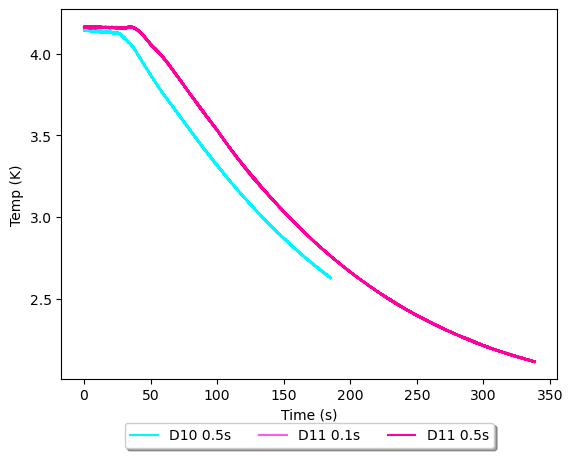

In [1564]:
list_dE = []
list_intercept = []
for i, r in enumerate(results):
    if r is None or r['dE'] is None:
        continue
    # print(r['dE'])



    # print(f'    {r['label']}\t ΔE = {r['dE']*1e3:.2f} ± {r['dE_err']*1e3:.2f} meV ({r["dE_err"]/r["dE"]*100:.2f}%)\t'
    #               f'ν₀ = {r['nu0']:.2e}  ± {r['nu0_err']:.2e}Hz  ({(r['nu0_err']/r['nu0'])*100:.2f}%)\t' 
    #               f'ν₀ = {np.log(r['nu0']):.2f}  ± {np.log(r['nu0_err']):.2f}Hz  ({(np.log(r['nu0_err'])/np.log(r['nu0']))*100:.2f}%) '
    #               f'R2 {r['R2']:.4f}')

    list_dE.append([r['dE'], r['dE_err']])
    list_intercept.append([np.log(r['nu0']), np.log(r['nu0_err'])])

    
    cooldown = r['cooldown']
    cooldown_time = cooldown[0]
    cooldown_temps = cooldown[1]
    # if i%2 == 0:
    #     plt_label = r['label']
    # else:
    #     plt_label = None
    plt.plot(np.array(cooldown_time)/60, cooldown_temps, color = r['color'], label=r['label'])
    # ax.scatter(r['T'], np.log(r['nu']))
plt.ylabel("Temp (K)")
plt.xlabel("Time (s)")
# plt.legend(handles[::2], labels[::2])
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1),
          ncol=5, fancybox=True, shadow=True)
plt.show()

[118.32795008 106.20354618]
[42.76112232 42.76112232 39.29719652 70.39488534]
[ 150.90327677  112.21818241  137.40440497  150.90327677  150.90327677
  124.55116985  165.16779524  150.90327677  137.40440497  124.55116985
  165.16779524  124.55116985  165.16779524  196.48598261  263.19369023
  150.90327677  165.16779524  150.90327677  242.28491107 1705.16856694
  569.26003208  798.53985634 2906.89763043 2906.89763043 1042.63450573
 3824.90447536 4226.35191982 5239.17660293]
[  22.44363648   22.44363648   28.81312061   26.1809385    33.03355905
   33.03355905   46.48611323   31.58646717   73.42047316   40.99850423
  298.7491052   422.22997489 1744.04464451]


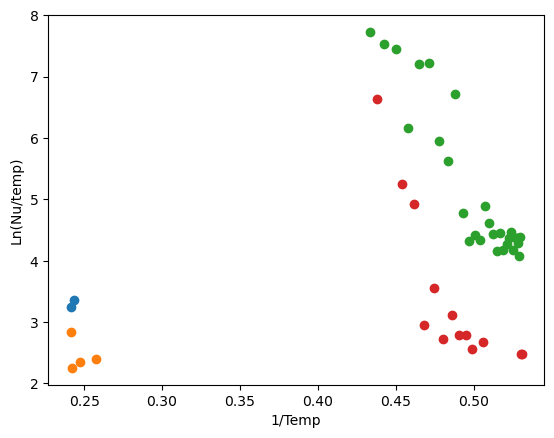

In [1565]:
for r in results:
    if r is None:
        continue

    
    nu = r['nu']
    temp = r[r'T']
    print(nu)
    
    constant_collection =  constants.h / (kB * kappa)
    plt.scatter(1/temp, np.log(nu/temp))

plt.xlabel("1/Temp")
plt.ylabel("Ln(Nu/temp)")
plt.show()



3 3
24.40772191954049


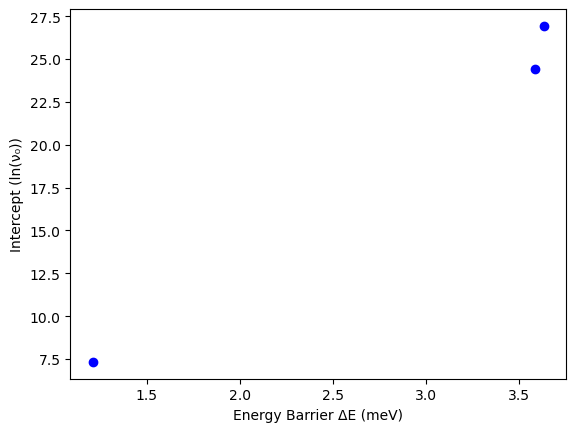

In [1566]:
# print(len(phys_fits))
# print(phys_fits[0][0]['dE'])

# for i, fit in enumerate(phys_fits):
#     dE = fit[0]['dE']
#     print(f"Dataset: {fit[0]['label']}, dE: {dE:.3f} eV")
#     plt.scatter(t_collection[i], dE)
#     plt.xlabel('Temperature (K)')
#     plt.ylabel('Energy Barrier (eV)')




print(len(intercept_collection), len(dE_collection))

plt.scatter(dE_collection, intercept_collection, color='blue', marker='o', label='τ=0.1s')
plt.xlabel('Energy Barrier ΔE (meV)')
plt.ylabel('Intercept (ln(ν₀))')

print(intercept_collection[-1])
# for i, intercept in enumerate(intercept_collection_01):
#     plt.scatter(1/(t_collection[i*2]), intercept, color='blue', marker='o', label='τ=0.1s' if i == 0 else "")
#     try:
#         plt.scatter(1/(t_collection[i*2+1]), intercept_collection_else[i], color='orange', marker='o', label='Other times' if i == 0 else "")
#     except IndexError:
#         pass    
#     plt.xlabel('1/T (1/K) (Temp at 0.5 probability)')
#     plt.ylabel('Intercept')
#     plt.legend(loc="upper left")

plt.show()

## Uncertainty estimate

The combined-fit error (±0.3 meV from the covariance matrix) measures only how precisely
a line was drawn through 27 points — it says nothing about whether those points from
different datasets are mutually consistent.

Since all six measurements are at the same spatial position and should in principle give
the same barrier, the **spread across the six individual fits** is the physically
appropriate uncertainty. The standard error on the mean of those six values captures
real sources of variability: different temperature ranges, different τ values, drift
between measurements, and any τ-dependent systematic (the τ = 0.1 s datasets
consistently give higher apparent barriers, which is itself worth investigating).

In [1567]:
odd = []
even = []

for i, res in enumerate(results):
    if i % 2 == 0:
        even.append(res)
        # print(f'Even index {i}: {res["label"]} added to even list.')
    else:
        odd.append(res)
    



dE_fits = np.array([f['dE'] for f in phys_fits])
labels_fit = [f['label'] for f in phys_fits]

mean_dE = np.mean(dE_fits)
std_dE  = np.std(dE_fits, ddof=1)
sem_dE  = std_dE / np.sqrt(len(dE_fits))




# print('Per-dataset ΔE (from physical model fits to full P(T) curves):')
# for lbl, dE in zip(labels_fit, dE_fits):
#     print(f'  {lbl:20s}  {dE*1e3:.2f} meV')

# print(f'\nn = {len(dE_fits)} datasets')
# print(f'Mean              : {mean_dE*1e3:.2f} meV')
# print(f'Std deviation     : {std_dE*1e3:.2f} meV')
# print(f'Std error on mean : {sem_dE*1e3:.2f} meV')
# print(f'\nResult: ΔE = {mean_dE*1e3:.1f} ± {sem_dE*1e3:.1f} meV  (mean ± SEM, n={len(dE_fits)})')
# print(f'  cf. combined-fit covariance error: ±{dE_all_err*1e3:.2f} meV  '
#       f'(underestimates by factor {sem_dE/dE_all_err:.1f})')

# ── Plot: per-dataset ΔE with mean ± std dev band ─────────────────────────────
fig_e, ax_e = plt.subplots(figsize=(10, 8))

# colors_e, markers_e  = [f['style']  for f in phys_fits]
colors_e, markers_e = zip(*[f['style'] for f in phys_fits])

# for i, (lbl, dE, col, mkr) in enumerate(zip(labels_fit, dE_fits, colors_e, markers_e)):
label_list = []
for i, (odd_item, even_item) in enumerate(zip(odd, even)):
    
    dE_odd = odd_item['dE']
    dE_even = even_item['dE']
    col_odd = odd_item['color']
    col_even = even_item['color']

    marker_odd = odd_item['marker']
    marker_even = even_item['marker']

      # Use only the dataset name (Dxx) for x-axis label
    print(odd_item['label'], even_item['label'],  f' {dE_odd*1e3:.3f} meV', f' {dE_even*1e3:.4f} meV')
    # print(label)
    label = odd_item['label'].split()[0]
    label_list.append(label)
    ax_e.plot(i, dE_odd*1e3, marker=marker_odd, color=col_odd, markersize=10, zorder=5)
    ax_e.plot(i, dE_even*1e3, marker=marker_even, color=col_even, markersize=10, zorder=5)

# Mean ± std dev band and ± SEM band
ax_e.axhspan((mean_dE - std_dE)*1e3, (mean_dE + std_dE)*1e3,
             alpha=0.12, color='steelblue', label='± std dev')
ax_e.axhspan((mean_dE - sem_dE)*1e3, (mean_dE + sem_dE)*1e3,
             alpha=0.25, color='steelblue', label='± SEM')
ax_e.axhline(mean_dE*1e3, color='steelblue', linewidth=1.5,
             linestyle='--', label=f'mean = {mean_dE*1e3:.1f} meV')

ax_e.set_xticks(range(len(odd)))



ax_e.set_xticklabels([label for label in label_list],
                      fontsize=16)
ax_e.tick_params(axis='y', labelsize=16)
ax_e.set_ylabel('ΔE  (meV)', fontsize=18)
ax_e.set_title(f'Per-dataset barriers   '
               f'ΔE = {mean_dE*1e3:.1f} ± {sem_dE*1e3:.1f} meV  (mean ± SEM, n={len(dE_fits)})',
               fontsize=18)
# ax_e.legend(fontsize=14)

ax_e.grid(True, axis='y', alpha=0.3)
ax_e.set_xlim(-0.5, len(odd) - 0.5)

plt.tight_layout()
plt.savefig('D24_D25_D26_barrier_summary.svg',
            format='svg', bbox_inches='tight', transparent=True)
plt.savefig('D24_D25_D26_barrier_summary.png',
            dpi=150, bbox_inches='tight', transparent=True)
# plt.show()
print('Saved barrier summary plot.')


TypeError: list indices must be integers or slices, not str

In [ ]:
print(f'\nSummary of per-dataset physical-model fits:')
for f in phys_fits:
    print(f'  {f["label"]:18s}  ΔE = {f["dE"]*1e3:.2f} ± {f["dE_err"]*1e3:.2f} meV'
          f'   ν₀ = {f["nu0"]:.2e} Hz')

print("---------------------------")
for res in results:
    if res is not None:
        print(f'  {res["label"]:18s}  ΔE = {res["dE"]*1e3:.2f} ± {res["dE_err"]*1e3:.2f} meV'
              f'   ν₀ = {res["nu0"]:.2e} Hz  R² = {res["R2"]:.4f}')


Summary of per-dataset physical-model fits:
  D24  τ=0.1s         ΔE = 9.95 ± 0.04 meV   ν₀ = 3.99e+22 Hz
  D25  τ=0.1s         ΔE = 7.08 ± 0.03 meV   ν₀ = 1.88e+17 Hz
  D26  τ=0.1s         ΔE = 10.29 ± 0.04 meV   ν₀ = 2.90e+23 Hz
  D20  τ=0.1s         ΔE = 8.76 ± 0.02 meV   ν₀ = 3.51e+17 Hz
  D21  τ=0.1s         ΔE = 13.87 ± 0.02 meV   ν₀ = 3.53e+24 Hz
  D22 τ=0.1s          ΔE = 15.26 ± 0.02 meV   ν₀ = 3.22e+28 Hz
  D27 τ=0.1s          ΔE = 9.35 ± 0.02 meV   ν₀ = 3.11e+20 Hz
  D28 τ=0.1s          ΔE = 11.58 ± 0.02 meV   ν₀ = 1.31e+25 Hz
  D31  τ=0.1s         ΔE = 10.63 ± 0.02 meV   ν₀ = 7.85e+29 Hz
  D32 τ=0.1s          ΔE = 10.10 ± 0.02 meV   ν₀ = 2.29e+19 Hz
  D33 τ=0.1s          ΔE = 15.39 ± 0.04 meV   ν₀ = 3.78e+28 Hz
  D34  τ=0.1s         ΔE = 6.19 ± 0.03 meV   ν₀ = 1.30e+14 Hz
  D35  τ=0.1s         ΔE = 14.86 ± 0.04 meV   ν₀ = 1.51e+23 Hz
  D36  τ=0.1s         ΔE = 7.72 ± 0.03 meV   ν₀ = 1.24e+17 Hz
  D37  τ=0.1s         ΔE = 5.49 ± 0.01 meV   ν₀ = 2.05e+11 Hz
  D38  τ=0.1s    